In [3]:
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier

In [4]:
train = pd.read_csv("../data/processed/train.csv")
cols = list(train.columns)
URL_COLS = cols[cols.index("length_url") : cols.index("statistical_report") + 1]
CONTENT_COLS = cols[cols.index("nb_hyperlinks") : cols.index("domain_with_copyright") + 1]
FINAL_COLS = [c for c in URL_COLS + CONTENT_COLS if c != "random_domain"]

In [5]:
X = train[FINAL_COLS]
y = (train["status"] == "phishing").astype(int)

In [6]:
# Modèle final : entraîné sur TOUT le train (le test reste verrouillé)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X, y)

In [7]:
# SHAP sur un échantillon de 500 URL (le calcul est lent : ~1 min 30)
X_sample = X.sample(500, random_state=42)
explainer = shap.TreeExplainer(rf)
sv = explainer(X_sample)[:, :, 1]     # contributions vers la classe 1 = phishing


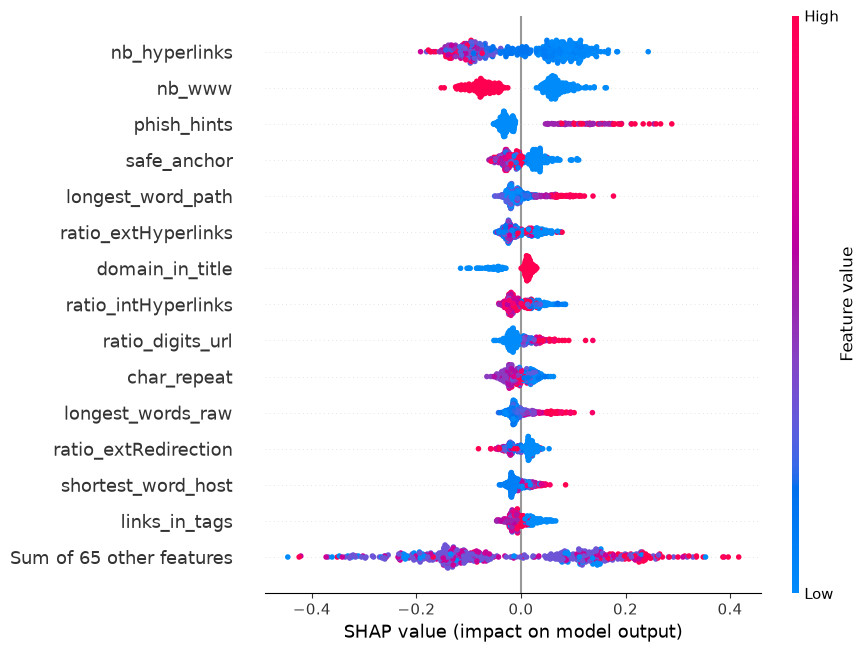

In [8]:
shap.plots.beeswarm(sv, max_display=15)

In [9]:
from sklearn.model_selection import GroupKFold

In [10]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
tr, va = next(cv.split(X, y, train["group"]))

In [11]:
rf_fold = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X.iloc[tr], y.iloc[tr])
X_va, y_va = X.iloc[va], y.iloc[va].values
proba_va = rf_fold.predict_proba(X_va)[:, 1]
explainer_fold = shap.TreeExplainer(rf_fold)

In [12]:
def explain(i, k=3):
    row = X_va.iloc[[i]]
    contrib = pd.Series(explainer_fold(row)[0, :, 1].values, index=FINAL_COLS)
    print(train["url"].iloc[va[i]][:90])
    print(f"  probabilité {proba_va[i]:.2f} | vrai statut : {train['status'].iloc[va[i]]}")
    for feat, value in contrib.sort_values(ascending=False).head(k).items():
        print(f"  + {feat} = {row[feat].iloc[0]}  (contribution {value:+.3f})")

In [13]:
# 1. Le phishing dont le modèle est le plus sûr
explain(int(np.argmax(np.where(y_va == 1, proba_va, -1))))
# 2. Une URL dans la file de revue (0,81 – 0,93)
explain(int(np.where((proba_va >= 0.81) & (proba_va < 0.93))[0][0]))
# 3. Une fausse alerte : une URL légitime au-dessus de 0,81
explain(int(np.where((y_va == 0) & (proba_va >= 0.81))[0][0]))

http://restbetgir1.blogspot.com
  probabilité 1.00 | vrai statut : phishing
  + nb_hyperlinks = 14  (contribution +0.129)
  + nb_www = 0  (contribution +0.103)
  + ratio_intHyperlinks = 0.071428571  (contribution +0.067)
http://shadetreetechnology.com/V4/validation/a111aedc8ae390eabcfa130e041a10a4
  probabilité 0.91 | vrai statut : phishing
  + longest_word_path = 32  (contribution +0.094)
  + longest_words_raw = 32  (contribution +0.072)
  + ratio_digits_url = 0.220779221  (contribution +0.061)
https://scenari.software/
  probabilité 0.83 | vrai statut : legitimate
  + nb_hyperlinks = 0  (contribution +0.106)
  + nb_www = 0  (contribution +0.095)
  + ratio_extHyperlinks = 0.0  (contribution +0.042)


In [14]:
PHRASES = {
    "nb_hyperlinks":       lambda v: f"seulement {v:.0f} lien(s) sur la page",
    "nb_www":              lambda v: "pas de « www » dans l'adresse" if v == 0 else f"« www » apparaît {v:.0f} fois",
    "phish_hints":         lambda v: f"{v:.0f} mot(s) suspect(s) dans l'URL (login, signin, admin…)",
    "safe_anchor":         lambda v: f"{v:.0f} % de liens vides ou JavaScript",
    "longest_word_path":   lambda v: f"jeton de {v:.0f} caractères dans le chemin (identifiant aléatoire ?)",
    "longest_words_raw":   lambda v: f"jeton de {v:.0f} caractères dans l'URL",
    "ratio_digits_url":    lambda v: f"{v:.0%} de chiffres dans l'URL",
    "domain_in_title":     lambda v: "le titre de la page ne mentionne pas le domaine" if v == 1 else "le titre mentionne le domaine",
    "ratio_extHyperlinks": lambda v: f"{v:.0%} des liens pointent vers d'autres sites",
    "ratio_intHyperlinks": lambda v: f"{v:.0%} seulement des liens restent sur le site",
}

def tier(p):
    if p >= 0.93:
        return "🔴 ALERTE HAUTE"
    if p >= 0.81:
        return "🟠 À REVOIR"
    return "⚪ pas d'alerte"

def soc_alert(i, k=3):
    row = X_va.iloc[[i]]
    contrib = pd.Series(explainer_fold(row)[0, :, 1].values, index=FINAL_COLS)
    print(f"{tier(proba_va[i])}  (probabilité {proba_va[i]:.2f})  {train['url'].iloc[va[i]][:80]}")
    for feat in contrib.sort_values(ascending=False).head(k).index:
        value = row[feat].iloc[0]
        print("   •", PHRASES.get(feat, lambda v: f"{feat} = {v}")(value))
    print()

for i in [int(np.argmax(np.where(y_va == 1, proba_va, -1))),
          int(np.where((proba_va >= 0.81) & (proba_va < 0.93))[0][0]),
          int(np.where((y_va == 0) & (proba_va >= 0.81))[0][0])]:
    soc_alert(i)


🔴 ALERTE HAUTE  (probabilité 1.00)  http://restbetgir1.blogspot.com
   • seulement 14 lien(s) sur la page
   • pas de « www » dans l'adresse
   • 7% seulement des liens restent sur le site

🟠 À REVOIR  (probabilité 0.91)  http://shadetreetechnology.com/V4/validation/a111aedc8ae390eabcfa130e041a10a4
   • jeton de 32 caractères dans le chemin (identifiant aléatoire ?)
   • jeton de 32 caractères dans l'URL
   • 22% de chiffres dans l'URL

🟠 À REVOIR  (probabilité 0.83)  https://scenari.software/
   • seulement 0 lien(s) sur la page
   • pas de « www » dans l'adresse
   • 0% des liens pointent vers d'autres sites

